# 🛠️ ChurnGuard AI — 2 : Preprocessing & Feature Engineering


Le notebook 1 (EDA) a **détecté** les problèmes et **mesuré** les signaux. Ce notebook les **traite** : nettoyage, création de variables, encodage, mise à l'échelle. 

### 🧭 Plan
| # | Section | Ce qu'on fait |
|---|---|---|
| 0 | Configuration | Imports, chargement des données brutes |
| 1 | Constats → décisions | Pourquoi chaque traitement (preuves de l'EDA) |
| 2 | Nettoyage | Corriger TotalCharges, simplifier les modalités |
| 3 | Cible & découpage | Encoder la cible, séparer train / test |
| 4 | Feature engineering | Créer de nouvelles variables utiles |
| 5 | Sélection de variables | Garder, exclure, surveiller |
| 6 | Encodage & échelle | Transformer en nombres (pipeline ajusté sur le train) |
| 7 | Contrôle de la matrice finale | Vérifier que tout est propre |
| 8 | Déséquilibre de classes | Calculer les poids de classe |
| 9 | Attributs sensibles | Exclusion et vérification des proxys (statistiques) |
| 10 | Export | Sauvegarder pour le notebook 3 |
| 11 | Synthèse | Bilan |

> **Règle d'or : pas de fuite de données.** On sépare train et test **avant** tout calcul appris (moyennes, catégories). Le test n'est jamais utilisé pour ajuster une transformation.

## 0. Configuration & chargement

In [3]:
import warnings, glob, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sns.set_theme(style='whitegrid', context='notebook')
C_STAY, C_CHURN, C_MAIN, C_GREY = '#2A9D8F', '#E76F51', '#264653', '#8D99AE'
PALETTE = {'No': C_STAY, 'Yes': C_CHURN}
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.spines.top': False, 'axes.spines.right': False})

SEED, TEST_SIZE = 42, 0.20

def h(text):
    display(Markdown(text))

In [4]:
# --- Recherche du fichier CSV brut ----------------------------------------------
NAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
CANDIDATES = [NAME, f'data/raw/{NAME}', f'../data/raw/{NAME}', f'../../data/raw/{NAME}']
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    for base in ['.', '..']:
        for p in glob.glob(os.path.join(base, '**', '*.csv'), recursive=True):
            try:
                if 'Churn' in pd.read_csv(p, nrows=2).columns:
                    path = p
                    break
            except Exception:
                pass
        if path:
            break
assert path is not None, 'CSV Telco introuvable : place-le dans data/raw/ ou à côté du notebook.'

# Dossier de sortie : <racine du projet>/data/processed
p_abs = Path(path).resolve()
ROOT = p_abs.parents[2] if (p_abs.parent.name == 'raw' and p_abs.parent.parent.name == 'data') else Path.cwd()
OUT_DIR = ROOT / 'data' / 'processed'
OUT_DIR.mkdir(parents=True, exist_ok=True)

raw_df = pd.read_csv(path)          # données brutes, gardées telles quelles
print(f'Données brutes : {raw_df.shape[0]:,} lignes × {raw_df.shape[1]} colonnes')
print(f'Sorties dans   : {OUT_DIR}')

Données brutes : 7,043 lignes × 21 colonnes
Sorties dans   : C:\Users\pc\Desktop\DATA\Hackathon_churn\data\processed


### Définitions communes
On regroupe ici les listes de colonnes et les petites fonctions utilisées plus loin, pour que le reste du notebook soit lisible.

In [5]:
# --- Groupes de colonnes ---------------------------------------------------------
SERVICE_COLS    = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
PROTECTION_COLS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
AUTO_PAY        = ['Bank transfer (automatic)', 'Credit card (automatic)']
TENURE_BINS     = [-1, 6, 12, 24, 48, 72]
TENURE_LABELS   = ['0-6', '7-12', '13-24', '25-48', '49-72']

# Variables que le modèle utilisera (définies maintenant, vérifiées section 4 et 5)
NUM_FEATURES   = ['tenure', 'MonthlyCharges', 'charge_trend', 'charge_per_service', 'n_addon_services', 'n_protection_services']
FLAG_FEATURES  = ['is_new_customer', 'auto_payment', 'mtm_fiber', 'mtm_echeck']
YN_FEATURES    = ['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                  'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling']
MULTI_FEATURES = ['Contract', 'InternetService', 'PaymentMethod']
ORDINAL_FEATURES = ['tenure_group']
ALL_FEATURES   = NUM_FEATURES + FLAG_FEATURES + YN_FEATURES + MULTI_FEATURES + ORDINAL_FEATURES

# Colonnes volontairement exclues du modèle
EXCLUDED = {
    'customerID':    "Identifiant unique, aucune valeur prédictive",
    'gender':        "Attribut sensible ; aucun lien avec le churn dans l'EDA (V = 0,000)",
    'SeniorCitizen': "Attribut sensible (âge) ; conservé à part pour l'audit d'équité",
    'TotalCharges':  "Redondant avec tenure × MonthlyCharges (r = 0,83 avec tenure) ; son information utile est portée par charge_trend",
    'avg_historical_charge': "Quasi identique à MonthlyCharges ; sert seulement à calculer charge_trend",
}

# --- Outil statistique : force du lien entre deux variables catégorielles --------
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    d = min(kc - 1, rc - 1)
    return np.sqrt(phi2c / d) if d > 0 else np.nan

---
## 1. Des constats de l'EDA aux décisions
**Objectif :** montrer que chaque traitement s'appuie sur un chiffre observé dans le notebook 1.

In [6]:
decisions = pd.DataFrame([
    ('TotalCharges en texte', '11 valeurs vides, toutes à tenure = 0 et Churn = No', 'Convertir en nombre ; vides → 0.0', "Ce sont des nouveaux clients pas encore facturés : 0 est la valeur logique. On garde ces 11 clients."),
    ('« No internet service » / « No phone service »', 'V(MultipleLines, PhoneService) = 1,00 ; services Internet liés entre eux (V ≈ 0,72)', 'Remplacer par « No »', "L'information est déjà dans InternetService et PhoneService."),
    ('SeniorCitizen codé 0/1', 'Les autres binaires sont Yes/No', 'Harmoniser en No/Yes', 'Format cohérent avant encodage.'),
    ('22 profils identiques hors ID', 'customerID unique', 'Conserver', 'Même forfait ne veut pas dire doublon.'),
    ('Aucune valeur aberrante', 'IQR et z-score : 0 outlier', 'Ne rien supprimer', 'Rien à corriger.'),
    ('Cible Yes/No, 26,54 % de churn', 'Ratio 2,77 : 1', 'Encoder en 0/1 ; split stratifié', 'Même proportion de churn dans train et test.'),
    ('tenure ↔ TotalCharges : r = 0,83', 'Multicolinéarité', 'Exclure TotalCharges', "TotalCharges ≈ tenure × MonthlyCharges : il n'apporte rien de nouveau."),
    ('47,4 % de churn à ≤ 12 mois vs 17,1 % au-delà', 'Effet non linéaire de tenure', 'Créer tenure_group et is_new_customer', "Rend l'effet de l'ancienneté plus lisible."),
    ('Mensuel + fibre : 54,6 % de churn, 62,2 % des churners', 'Churn concentré', 'Créer mtm_fiber', 'Capte une interaction importante.'),
    ('Chèque électronique 45,3 % vs carte automatique ≈ 15 %', 'PaymentMethod : V = 0,30', 'Créer auto_payment et mtm_echeck', 'Résume le mode de paiement et son lien avec le contrat.'),
    ('OnlineSecurity (V = 0,35) et TechSupport (V = 0,34)', 'Services corrélés entre eux', 'Créer n_addon_services et n_protection_services', "Un compteur résume l'engagement du client."),
    ('Partis : facture moyenne 74,44 vs 61,27', 'Facture plus élevée chez les partis', 'Créer charge_trend et charge_per_service', "Mesure l'évolution du prix et la valeur perçue par service."),
    ('gender : V = 0,000 (p = 0,47)', 'Aucun lien avec le churn', 'Exclure du modèle', "Aucune perte d'information, risque d'équité écarté."),
    ('SeniorCitizen : V = 0,150', 'Lié à l\'âge', 'Exclure du modèle, garder pour l\'audit', "Responsible AI : on pourra mesurer l'équité sans utiliser cet attribut."),
], columns=['constat EDA', 'preuve', 'décision', 'pourquoi'])
display(decisions)

,constat EDA,preuve,décision,pourquoi
0,TotalCharges en texte,"11 valeurs vides, toutes à tenure = 0 et Churn...",Convertir en nombre ; vides → 0.0,Ce sont des nouveaux clients pas encore factur...
1,« No internet service » / « No phone service »,"V(MultipleLines, PhoneService) = 1,00 ; servic...",Remplacer par « No »,L'information est déjà dans InternetService et...
2,SeniorCitizen codé 0/1,Les autres binaires sont Yes/No,Harmoniser en No/Yes,Format cohérent avant encodage.
3,22 profils identiques hors ID,customerID unique,Conserver,Même forfait ne veut pas dire doublon.
4,Aucune valeur aberrante,IQR et z-score : 0 outlier,Ne rien supprimer,Rien à corriger.
5,"Cible Yes/No, 26,54 % de churn","Ratio 2,77 : 1",Encoder en 0/1 ; split stratifié,Même proportion de churn dans train et test.
6,"tenure ↔ TotalCharges : r = 0,83",Multicolinéarité,Exclure TotalCharges,TotalCharges ≈ tenure × MonthlyCharges : il n'...
7,"47,4 % de churn à ≤ 12 mois vs 17,1 % au-delà",Effet non linéaire de tenure,Créer tenure_group et is_new_customer,Rend l'effet de l'ancienneté plus lisible.
8,"Mensuel + fibre : 54,6 % de churn, 62,2 % des ...",Churn concentré,Créer mtm_fiber,Capte une interaction importante.
9,"Chèque électronique 45,3 % vs carte automatiqu...","PaymentMethod : V = 0,30",Créer auto_payment et mtm_echeck,Résume le mode de paiement et son lien avec le...


---
## 2. Nettoyage
**Objectif :** corriger les problèmes détectés. Le nettoyage ne dépend d'aucune statistique calculée sur les données : on peut donc l'appliquer à tout le jeu avant le découpage sans risque de fuite.

La fonction `clean_raw` fait quatre choses :
1. Supprime les espaces parasites dans les textes.
2. Convertit `TotalCharges` en nombre (les vides, qui concernent tenure = 0, deviennent 0).
3. Transforme `SeniorCitizen` de 0/1 en No/Yes.
4. Remplace « No internet service » et « No phone service » par « No ».

In [7]:
def clean_raw(raw):
    d = raw.copy()
    for c in d.select_dtypes(include=['object', 'string']).columns:
        d[c] = d[c].astype(str).str.strip()
    d['TotalCharges'] = pd.to_numeric(d['TotalCharges'].replace('', np.nan), errors='coerce')
    d.loc[d['TotalCharges'].isna() & (d['tenure'] == 0), 'TotalCharges'] = 0.0
    d['SeniorCitizen'] = d['SeniorCitizen'].astype(str).map({'0': 'No', '1': 'Yes', 'No': 'No', 'Yes': 'Yes'})
    for c in SERVICE_COLS:
        d[c] = d[c].replace({'No internet service': 'No'})
    d['MultipleLines'] = d['MultipleLines'].replace({'No phone service': 'No'})
    return d

clean = clean_raw(raw_df)
blank_mask = raw_df['TotalCharges'].astype(str).str.strip().eq('')

audit = [('TotalCharges : espaces vides → 0.0', int(blank_mask.sum())),
         ('SeniorCitizen : 0/1 → No/Yes', len(raw_df))]
audit += [(f'{c} : « No internet service » → « No »', int((raw_df[c] == 'No internet service').sum())) for c in SERVICE_COLS]
audit += [('MultipleLines : « No phone service » → « No »', int((raw_df['MultipleLines'] == 'No phone service').sum()))]
h('### Journal des corrections')
display(pd.DataFrame(audit, columns=['correction', 'lignes concernées']))
print(f'Valeurs manquantes après nettoyage : {int(clean.isna().sum().sum())}   |   TotalCharges est maintenant : {clean["TotalCharges"].dtype}')

### Journal des corrections

,correction,lignes concernées
0,TotalCharges : espaces vides → 0.0,11
1,SeniorCitizen : 0/1 → No/Yes,7043
2,OnlineSecurity : « No internet service » → « No »,1526
3,OnlineBackup : « No internet service » → « No »,1526
4,DeviceProtection : « No internet service » → «...,1526
5,TechSupport : « No internet service » → « No »,1526
6,StreamingTV : « No internet service » → « No »,1526
7,StreamingMovies : « No internet service » → « ...,1526
8,MultipleLines : « No phone service » → « No »,682


Valeurs manquantes après nettoyage : 0   |   TotalCharges est maintenant : float64


### Avant / après

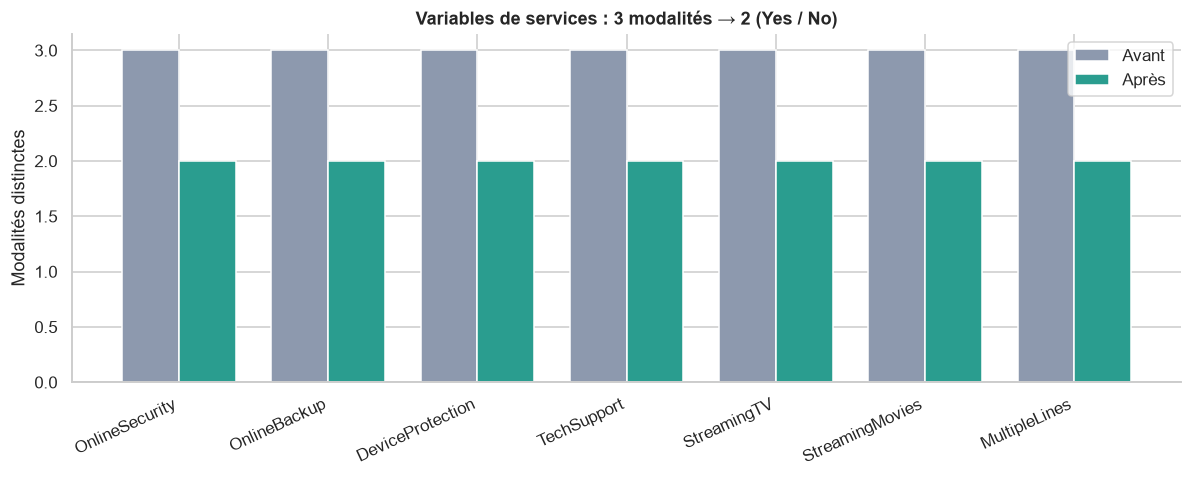

,TotalCharges brut,TotalCharges nettoyé,tenure
0,' ',0.000,0
1,' ',0.000,0
2,' ',0.000,0
3,' ',0.000,0
4,' ',0.000,0


In [8]:
h('### Avant / après')
cols = SERVICE_COLS + ['MultipleLines']
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(cols)); w = .38
ax.bar(x - w / 2, raw_df[cols].nunique(), w, color=C_GREY, label='Avant')
ax.bar(x + w / 2, clean[cols].nunique(), w, color=C_STAY, label='Après')
ax.set_xticks(x); ax.set_xticklabels(cols, rotation=25, ha='right'); ax.set_ylabel('Modalités distinctes')
ax.set_title('Variables de services : 3 modalités → 2 (Yes / No)'); ax.legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame({'TotalCharges brut': raw_df.loc[blank_mask, 'TotalCharges'].map(repr).head(5).values,
                      'TotalCharges nettoyé': clean.loc[blank_mask, 'TotalCharges'].head(5).values,
                      'tenure': clean.loc[blank_mask, 'tenure'].head(5).values}))

---
## 3. Variable cible et découpage train / test
**Objectif :** transformer la cible en 0/1, puis **mettre de côté le jeu de test avant toute transformation apprise**.

> Si on calculait une moyenne sur tout le jeu avant de le découper, des informations du test passeraient dans l'entraînement et le score serait trop optimiste. C'est ce qu'on appelle une **fuite de données**.

Le découpage est **stratifié** : le taux de churn est le même dans le train et le test.

,clients,churners,taux de churn
Total,7043,1869,0.265
Train (80%),5634,1495,0.265
Test (20%),1409,374,0.265


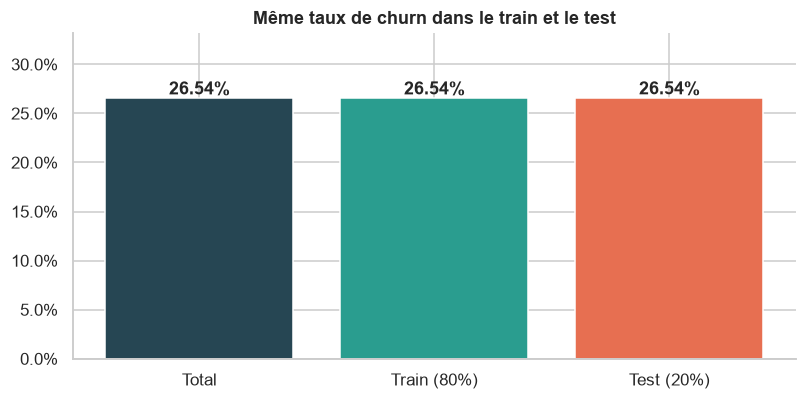

In [9]:
y = (clean['Churn'] == 'Yes').astype(int)         # 1 = parti, 0 = resté

idx_train, idx_test = train_test_split(clean.index, test_size=TEST_SIZE, stratify=y, random_state=SEED)
train_clean, test_clean = clean.loc[idx_train].copy(), clean.loc[idx_test].copy()
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

split_table = pd.DataFrame({'clients': [len(y), len(y_train), len(y_test)],
                            'churners': [y.sum(), y_train.sum(), y_test.sum()],
                            'taux de churn': [y.mean(), y_train.mean(), y_test.mean()]},
                           index=['Total', f'Train ({1 - TEST_SIZE:.0%})', f'Test ({TEST_SIZE:.0%})'])
display(split_table)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(split_table.index, split_table['taux de churn'], color=[C_MAIN, C_STAY, C_CHURN])
for i, v in enumerate(split_table['taux de churn']):
    ax.text(i, v + .004, f'{v:.2%}', ha='center', fontweight='bold')
ax.set_ylim(0, split_table['taux de churn'].max() * 1.25); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title('Même taux de churn dans le train et le test')
plt.tight_layout(); plt.show()

---
## 4. Feature engineering
**Objectif :** créer des variables qui rendent plus visibles les signaux repérés en EDA.

La fonction `engineer_features` calcule chaque variable **ligne par ligne** (aucune statistique globale), donc elle s'applique de la même façon au train et au test sans fuite.

| Variable | Définition |
|---|---|
| `n_addon_services` | Nombre de services optionnels actifs (0 à 6) |
| `n_protection_services` | Nombre de services de protection actifs (0 à 4) |
| `tenure_group` | Tranche d'ancienneté : 0-6, 7-12, 13-24, 25-48, 49-72 mois |
| `is_new_customer` | 1 si ancienneté ≤ 12 mois |
| `auto_payment` | 1 si paiement automatique (virement ou carte) |
| `avg_historical_charge` | TotalCharges / tenure (facture moyenne payée jusqu'ici) — *intermédiaire* |
| `charge_trend` | Prix actuel par rapport à la facture moyenne passée (hausse ou baisse) |
| `charge_per_service` | MonthlyCharges / (1 + nombre de services) |
| `mtm_fiber` | 1 si contrat mensuel ET fibre optique |
| `mtm_echeck` | 1 si contrat mensuel ET chèque électronique |

In [10]:
def engineer_features(d):
    f = d.copy()
    f['n_addon_services']      = (f[SERVICE_COLS] == 'Yes').sum(axis=1).astype(int)
    f['n_protection_services'] = (f[PROTECTION_COLS] == 'Yes').sum(axis=1).astype(int)
    f['tenure_group']          = pd.cut(f['tenure'], bins=TENURE_BINS, labels=TENURE_LABELS).astype(str)
    f['is_new_customer']       = (f['tenure'] <= 12).astype(int)
    f['auto_payment']          = f['PaymentMethod'].isin(AUTO_PAY).astype(int)
    # Facture moyenne passée (pour tenure = 0, aucune facture : on prend le prix actuel)
    avg = f['TotalCharges'] / f['tenure'].where(f['tenure'] > 0)
    f['avg_historical_charge'] = avg.fillna(f['MonthlyCharges'])
    f['charge_trend']          = (f['MonthlyCharges'] / f['avg_historical_charge'] - 1).fillna(0.0)
    f['charge_per_service']    = f['MonthlyCharges'] / (1 + f['n_addon_services'])
    f['mtm_fiber']             = ((f['Contract'] == 'Month-to-month') & (f['InternetService'] == 'Fiber optic')).astype(int)
    f['mtm_echeck']            = ((f['Contract'] == 'Month-to-month') & (f['PaymentMethod'] == 'Electronic check')).astype(int)
    return f

train_fe = engineer_features(train_clean)
test_fe  = engineer_features(test_clean)

created = ['n_addon_services', 'n_protection_services', 'tenure_group', 'is_new_customer', 'auto_payment',
           'avg_historical_charge', 'charge_trend', 'charge_per_service', 'mtm_fiber', 'mtm_echeck']
display(train_fe[created].head(8))

,n_addon_services,n_protection_services,tenure_group,is_new_customer,auto_payment,avg_historical_charge,charge_trend,charge_per_service,mtm_fiber,mtm_echeck
3738,3,1,25-48,0,0,48.619,0.012,12.300,0,1
3151,1,1,13-24,0,0,76.770,-0.022,37.550,1,0
4860,3,3,13-24,0,0,45.412,-0.107,10.137,0,0
3867,4,2,25-48,0,1,73.296,0.003,14.700,0,0
3810,0,0,0-6,1,0,44.550,0.000,44.550,0,1
2666,5,3,49-72,0,1,78.729,0.010,13.250,0,0
2645,0,0,0-6,1,1,19.800,0.000,19.800,0,0
189,1,1,25-48,0,1,59.477,-0.048,28.300,0,0


### 4.2 Les nouvelles variables sont-elles informatives ? (calculé sur le train)

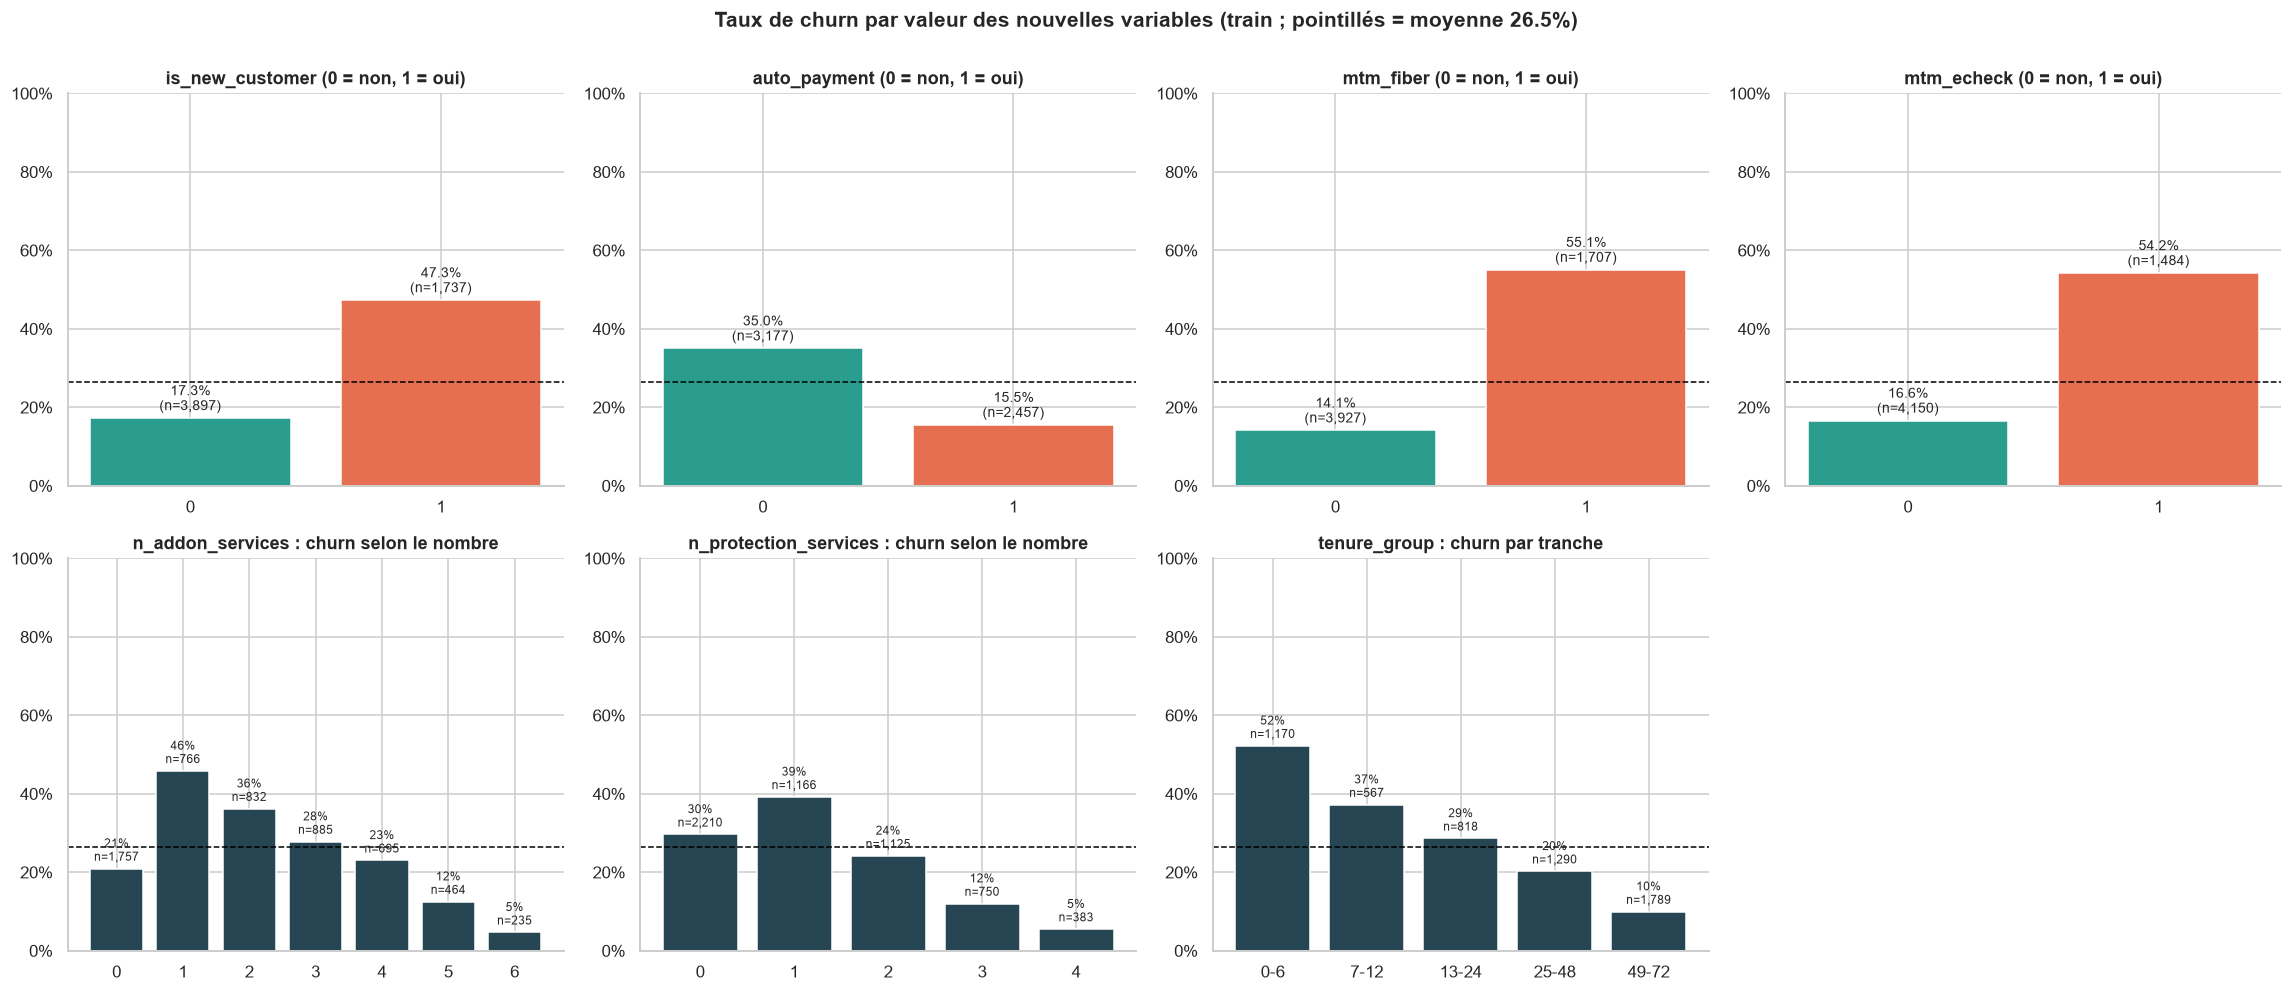

,clients (valeur = 1),churn si 1,churn si 0,lift si 1
variable,,,,
is_new_customer,1737,0.473,0.173,1.783
auto_payment,2457,0.155,0.350,0.586
mtm_fiber,1707,0.551,0.141,2.075
mtm_echeck,1484,0.542,0.166,2.044


Lift = taux de churn du groupe / taux global. Lift > 1 : le groupe part plus que la moyenne.


In [11]:
h('### 4.2 Les nouvelles variables sont-elles informatives ? (calculé sur le train)')
base = y_train.mean()
flags = ['is_new_customer', 'auto_payment', 'mtm_fiber', 'mtm_echeck']

fig, axes = plt.subplots(2, 4, figsize=(21, 9))
axes = axes.ravel()
for ax, f in zip(axes[:4], flags):
    g = y_train.groupby(train_fe[f]).agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color=[C_STAY, C_CHURN])
    for i, (r, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, r + .02, f'{r:.1%}\n(n={n:,})', ha='center', fontsize=9)
    ax.axhline(base, color='black', ls='--', lw=1); ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title(f'{f} (0 = non, 1 = oui)')
for ax, f in zip(axes[4:6], ['n_addon_services', 'n_protection_services']):
    g = y_train.groupby(train_fe[f]).agg(['mean', 'size'])
    ax.bar(g.index.astype(str), g['mean'], color=C_MAIN)
    for i, (r, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(i, r + .02, f'{r:.0%}\nn={n:,}', ha='center', fontsize=8)
    ax.axhline(base, color='black', ls='--', lw=1); ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_title(f'{f} : churn selon le nombre')
g = y_train.groupby(train_fe['tenure_group']).agg(['mean', 'size']).reindex(TENURE_LABELS)
axes[6].bar(g.index, g['mean'], color=C_MAIN)
for i, (r, n) in enumerate(zip(g['mean'], g['size'])):
    axes[6].text(i, r + .02, f'{r:.0%}\nn={n:,}', ha='center', fontsize=8)
axes[6].axhline(base, color='black', ls='--', lw=1); axes[6].set_ylim(0, 1)
axes[6].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[6].set_title('tenure_group : churn par tranche')
axes[7].axis('off')
fig.suptitle(f'Taux de churn par valeur des nouvelles variables (train ; pointillés = moyenne {base:.1%})', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout(); plt.show()

rows = []
for f in flags:
    g = y_train.groupby(train_fe[f]).agg(['mean', 'size'])
    rows.append({'variable': f, 'clients (valeur = 1)': int(g.loc[1, 'size']), 'churn si 1': g.loc[1, 'mean'],
                 'churn si 0': g.loc[0, 'mean'], 'lift si 1': g.loc[1, 'mean'] / base})
display(pd.DataFrame(rows).set_index('variable'))
print('Lift = taux de churn du groupe / taux global. Lift > 1 : le groupe part plus que la moyenne.')

### 4.3 Variables numériques créées : comparaison partis vs restés (train)

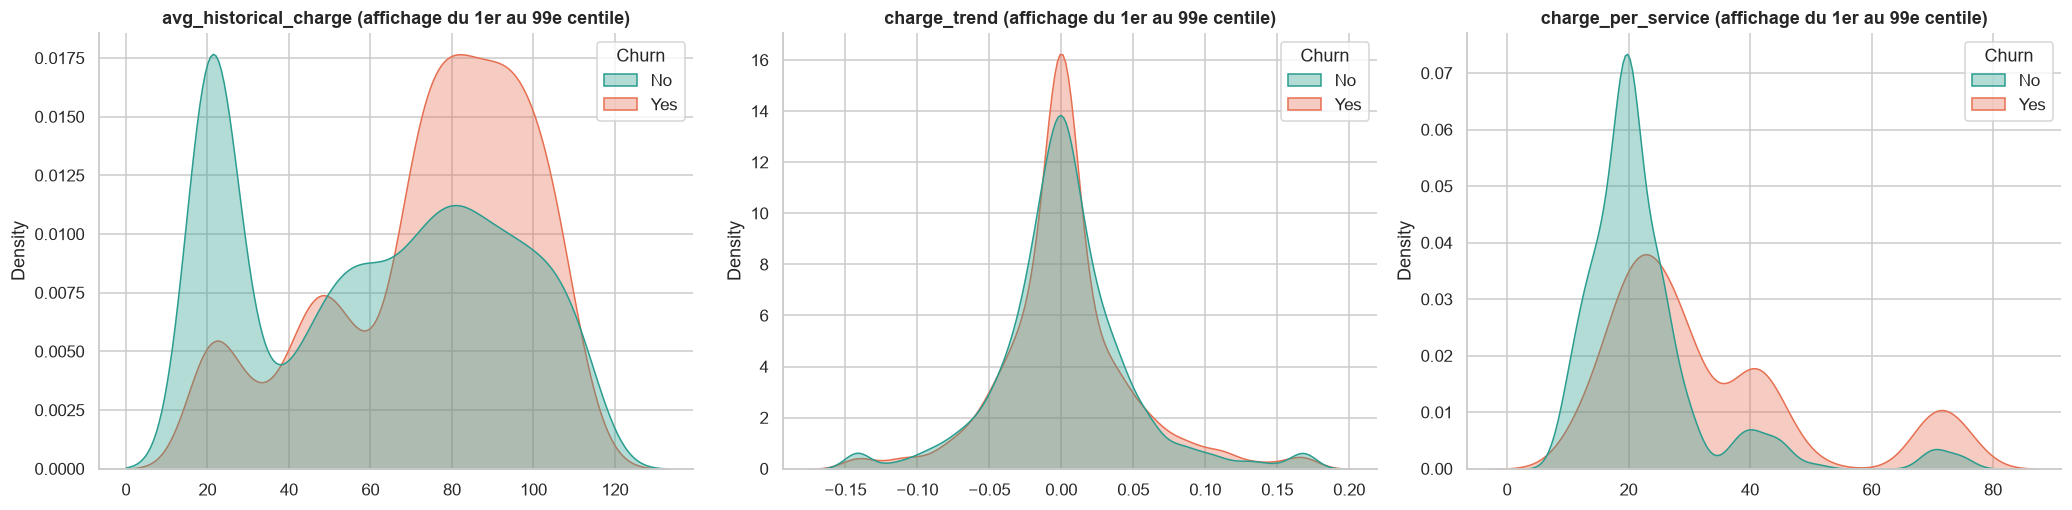

,médiane partis,médiane restés,p-value (Mann-Whitney),effet (rang-bisérial)
variable,,,,
avg_historical_charge,79.774,63.977,0.000,0.248
charge_trend,0.000,0.000,0.622,0.009
charge_per_service,26.700,20.040,0.000,0.434


Lecture : p < 0,05 = les deux groupes diffèrent vraiment ; l'effet va de −1 à +1 (0 = aucune différence).


In [12]:
h('### 4.3 Variables numériques créées : comparaison partis vs restés (train)')
new_num = ['avg_historical_charge', 'charge_trend', 'charge_per_service']

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, f in zip(axes, new_num):
    s = train_fe[f]
    lo, hi = s.quantile([.01, .99])
    d = pd.DataFrame({'v': s.clip(lo, hi), 'Churn': train_clean['Churn']})
    sns.kdeplot(data=d, x='v', hue='Churn', palette=PALETTE, fill=True, common_norm=False, alpha=.35, ax=ax)
    ax.set_title(f'{f} (affichage du 1er au 99e centile)'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

rows = []
for f in new_num:
    a, b = train_fe.loc[y_train == 1, f], train_fe.loc[y_train == 0, f]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    rows.append({'variable': f, 'médiane partis': a.median(), 'médiane restés': b.median(), 'p-value (Mann-Whitney)': p,
                 'effet (rang-bisérial)': 2 * u / (len(a) * len(b)) - 1})
display(pd.DataFrame(rows).set_index('variable'))
print("Lecture : p < 0,05 = les deux groupes diffèrent vraiment ; l'effet va de −1 à +1 (0 = aucune différence).")

---
## 5. Sélection de variables
**Objectif :** décider quelles colonnes entrent dans le modèle. Deux questions : y a-t-il des **doublons d'information** (multicolinéarité) ? y a-t-il des colonnes à **exclure pour des raisons éthiques** ?

Le **VIF** (facteur d'inflation de la variance) mesure à quel point une variable est déjà expliquée par les autres. Au-dessus de 10, elle fait doublon.

### 5.1 Avant : variables numériques d'origine

,VIF
tenure,5.931
MonthlyCharges,3.230
TotalCharges,9.683


Corrélation tenure ↔ TotalCharges : 0.83  → TotalCharges est exclue.


### 5.2 Vérification de avg_historical_charge

Corrélation MonthlyCharges ↔ avg_historical_charge : 1.00
VIF si on la gardait : MonthlyCharges = 472, avg_historical_charge = 471  → quasi doublon, donc exclue (elle sert seulement à calculer charge_trend).


### 5.3 Après : variables numériques retenues

,VIF
tenure,1.393
MonthlyCharges,5.898
charge_trend,1.001
charge_per_service,3.333
n_addon_services,17.296
n_protection_services,7.176


Variables retenues avec VIF > 10 : ['n_addon_services']


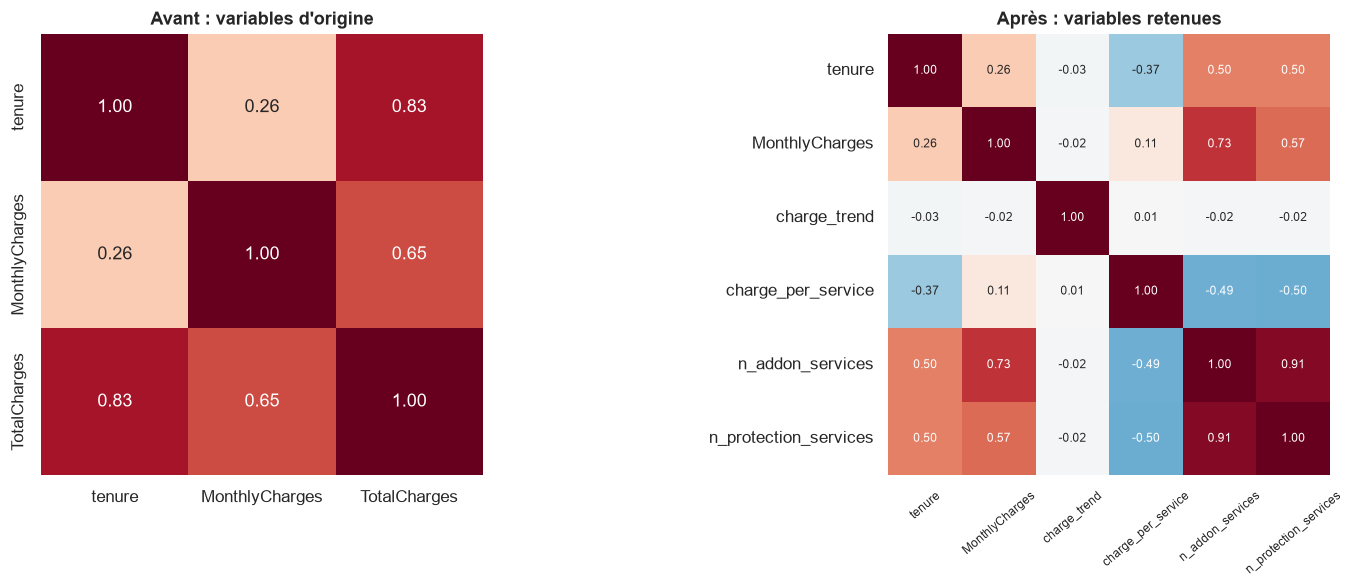

In [13]:
def vif_table(frame):
    z = (frame - frame.mean()) / frame.std(ddof=0)
    R = np.corrcoef(z.values, rowvar=False)
    return pd.Series(np.diag(np.linalg.pinv(R)), index=frame.columns)

h('### 5.1 Avant : variables numériques d\'origine')
display(vif_table(train_fe[['tenure', 'MonthlyCharges', 'TotalCharges']]).to_frame('VIF'))
print(f"Corrélation tenure ↔ TotalCharges : {train_fe['tenure'].corr(train_fe['TotalCharges']):.2f}  → TotalCharges est exclue.")

h('### 5.2 Vérification de avg_historical_charge')
print(f"Corrélation MonthlyCharges ↔ avg_historical_charge : {train_fe['MonthlyCharges'].corr(train_fe['avg_historical_charge']):.2f}")
vif_c = vif_table(train_fe[NUM_FEATURES + ['avg_historical_charge']])
print(f"VIF si on la gardait : MonthlyCharges = {vif_c['MonthlyCharges']:.0f}, avg_historical_charge = {vif_c['avg_historical_charge']:.0f}  → quasi doublon, donc exclue (elle sert seulement à calculer charge_trend).")

h('### 5.3 Après : variables numériques retenues')
vif_b = vif_table(train_fe[NUM_FEATURES])
display(vif_b.to_frame('VIF'))
print('Variables retenues avec VIF > 10 :', list(vif_b[vif_b > 10].index) or 'aucune')

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(train_fe[['tenure', 'MonthlyCharges', 'TotalCharges']].corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True, cbar=False, ax=ax[0])
ax[0].set_title('Avant : variables d\'origine')
sns.heatmap(train_fe[NUM_FEATURES].corr(), annot=True, fmt='.2f', annot_kws={'size': 8}, cmap='RdBu_r', vmin=-1, vmax=1, square=True, cbar=False, ax=ax[1])
ax[1].set_title('Après : variables retenues'); ax[1].tick_params(axis='x', labelrotation=40, labelsize=8)
plt.tight_layout(); plt.show()

In [14]:
h('### 5.4 Registre : variables exclues, conservées, à surveiller')
gov = [(c, 'EXCLUE', why) for c, why in EXCLUDED.items()]
gov += [('Partner, Dependents', 'CONSERVÉES, À SURVEILLER', "Situation familiale : lien faible avec le churn (V ≈ 0,15) ; peut être jugée sensible selon le contexte.")]
gov += [('Toutes les autres', 'CONSERVÉES', 'Contrat, services, paiement, facturation, ancienneté : variables commerciales sur lesquelles on peut agir.')]
display(pd.DataFrame(gov, columns=['colonne(s)', 'décision', 'raison']).set_index('colonne(s)'))
print(f'{len(ALL_FEATURES)} variables avant encodage.')

### 5.4 Registre : variables exclues, conservées, à surveiller

,décision,raison
colonne(s),,
customerID,EXCLUE,"Identifiant unique, aucune valeur prédictive"
gender,EXCLUE,Attribut sensible ; aucun lien avec le churn d...
SeniorCitizen,EXCLUE,Attribut sensible (âge) ; conservé à part pour...
TotalCharges,EXCLUE,"Redondant avec tenure × MonthlyCharges (r = 0,..."
avg_historical_charge,EXCLUE,Quasi identique à MonthlyCharges ; sert seulem...
"Partner, Dependents","CONSERVÉES, À SURVEILLER",Situation familiale : lien faible avec le chur...
Toutes les autres,CONSERVÉES,"Contrat, services, paiement, facturation, anci..."


25 variables avant encodage.


---
## 6. Encodage et mise à l'échelle
**Objectif :** transformer toutes les variables en nombres.

| Type | Variables | Traitement |
|---|---|---|
| Numériques | tenure, MonthlyCharges, charge_trend, charge_per_service, n_addon_services, n_protection_services | Mise à l'échelle (moyenne 0, écart-type 1) |
| Drapeaux 0/1 | is_new_customer, auto_payment, mtm_fiber, mtm_echeck | Inchangés |
| Oui / Non | Partner, Dependents, services, PaperlessBilling… | Une colonne 0/1 par variable |
| Plusieurs modalités | Contract, InternetService, PaymentMethod | Une colonne 0/1 par modalité (*one-hot*) |
| Ordonnée | tenure_group | Chiffres 0 à 4 dans l'ordre des tranches |

Le pipeline est **ajusté (`fit`) sur le train seulement**, puis **appliqué (`transform`) au test**. On produit deux versions : **avec** mise à l'échelle (pour les modèles linéaires) et **sans** (pour les arbres).

In [15]:
def build_preprocessor(scale=True):
    ct = ColumnTransformer([
        ('num',  StandardScaler() if scale else 'passthrough', NUM_FEATURES),
        ('flags', 'passthrough', FLAG_FEATURES),
        ('yn',   OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), YN_FEATURES),
        ('multi', OneHotEncoder(handle_unknown='ignore', sparse_output=False), MULTI_FEATURES),
        ('tenure_ord', OrdinalEncoder(categories=[TENURE_LABELS]), ORDINAL_FEATURES),
    ], verbose_feature_names_out=False)
    ct.set_output(transform='pandas')
    return ct

X_train, X_test = train_fe[ALL_FEATURES], test_fe[ALL_FEATURES]

pre_scaled = build_preprocessor(scale=True)       # version avec mise à l'échelle
pre_tree   = build_preprocessor(scale=False)      # version sans mise à l'échelle

Xtr_scaled = pre_scaled.fit_transform(X_train)    # ajusté sur le TRAIN
Xte_scaled = pre_scaled.transform(X_test)         # appliqué au TEST
Xtr_tree   = pre_tree.fit_transform(X_train)
Xte_tree   = pre_tree.transform(X_test)

print(f'X_train : {Xtr_scaled.shape}   |   X_test : {Xte_scaled.shape}')
h('**Colonnes de la matrice finale**')
print(', '.join(Xtr_scaled.columns))
display(Xtr_tree.head(6))

X_train : (5634, 32)   |   X_test : (1409, 32)


**Colonnes de la matrice finale**

tenure, MonthlyCharges, charge_trend, charge_per_service, n_addon_services, n_protection_services, is_new_customer, auto_payment, mtm_fiber, mtm_echeck, Partner_Yes, Dependents_Yes, PhoneService_Yes, MultipleLines_Yes, OnlineSecurity_Yes, OnlineBackup_Yes, DeviceProtection_Yes, TechSupport_Yes, StreamingTV_Yes, StreamingMovies_Yes, PaperlessBilling_Yes, Contract_Month-to-month, Contract_One year, Contract_Two year, InternetService_DSL, InternetService_Fiber optic, InternetService_No, PaymentMethod_Bank transfer (automatic), PaymentMethod_Credit card (automatic), PaymentMethod_Electronic check, PaymentMethod_Mailed check, tenure_group


,tenure,MonthlyCharges,charge_trend,charge_per_service,n_addon_services,n_protection_services,is_new_customer,auto_payment,mtm_fiber,mtm_echeck,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,OnlineSecurity_Yes,OnlineBackup_Yes,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,PaperlessBilling_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_group
3738,35,49.200,0.012,12.300,3,1,0,0,0,1,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,3.000
3151,15,75.100,-0.022,37.550,1,1,0,0,1,0,1.000,1.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,2.000
4860,13,40.550,-0.107,10.137,3,3,0,0,0,0,1.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,2.000
3867,26,73.500,0.003,14.700,4,2,0,1,0,0,1.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,1.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,3.000
3810,1,44.550,0.000,44.550,0,0,1,0,0,1,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
2666,66,79.500,0.010,13.250,5,3,0,1,0,0,0.000,1.000,1.000,0.000,0.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,4.000


In [16]:
h('### 6.2 Le scaler a été calibré sur le train')
proof = pd.DataFrame({'moyenne train': Xtr_scaled[NUM_FEATURES].mean(), 'écart-type train': Xtr_scaled[NUM_FEATURES].std(ddof=0),
                      'moyenne test': Xte_scaled[NUM_FEATURES].mean(), 'écart-type test': Xte_scaled[NUM_FEATURES].std(ddof=0)})
display(proof)
print("Train : moyenne 0 et écart-type 1 par construction. Test : proche mais pas exactement, car il n'a pas servi à calibrer le scaler.")

### 6.2 Le scaler a été calibré sur le train

,moyenne train,écart-type train,moyenne test,écart-type test
tenure,-0.000,1.000,-0.023,0.998
MonthlyCharges,-0.000,1.000,-0.028,0.992
charge_trend,-0.000,1.000,0.031,1.018
charge_per_service,-0.000,1.000,0.054,1.085
n_addon_services,0.000,1.000,-0.054,0.980
n_protection_services,-0.000,1.000,-0.046,0.994


Train : moyenne 0 et écart-type 1 par construction. Test : proche mais pas exactement, car il n'a pas servi à calibrer le scaler.


---
## 7. Contrôle de la matrice finale
**Objectif :** vérifier d'un coup d'œil que la matrice est propre : pas de manquants, bonnes dimensions, train et test comparables.

In [17]:
summary = pd.DataFrame({
    'train': [Xtr_scaled.shape[0], Xtr_scaled.shape[1], int(Xtr_scaled.isna().sum().sum()), int((Xtr_scaled.nunique() <= 1).sum())],
    'test':  [Xte_scaled.shape[0], Xte_scaled.shape[1], int(Xte_scaled.isna().sum().sum()), int((Xte_scaled.nunique() <= 1).sum())],
}, index=['lignes', 'colonnes', 'valeurs manquantes', 'colonnes constantes'])
display(summary)

,train,test
lignes,5634,1409
colonnes,32,32
valeurs manquantes,0,0
colonnes constantes,0,0


### Train vs test : les moyennes sont-elles comparables ?

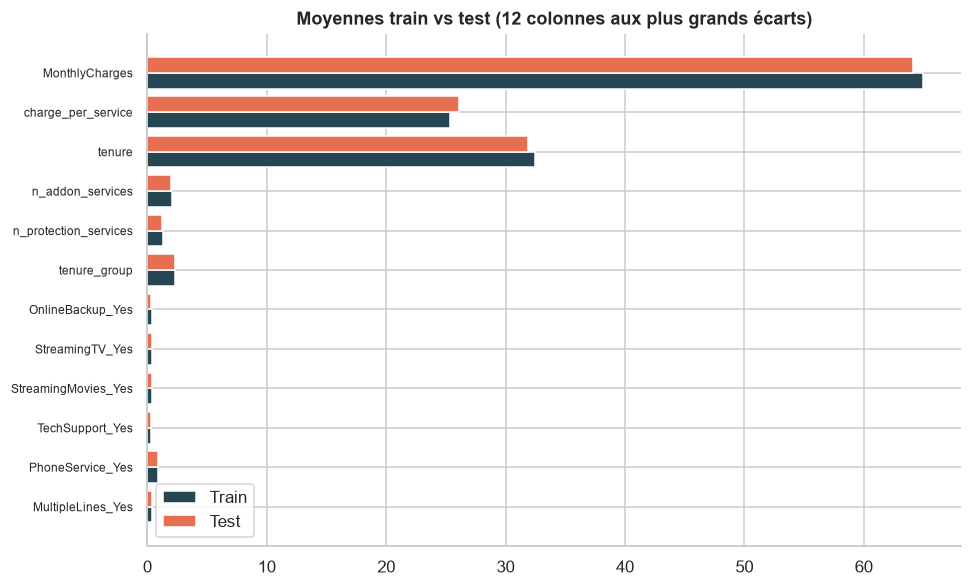

Plus grand écart absolu entre les moyennes : 0.841 (MonthlyCharges).


In [18]:
h('### Train vs test : les moyennes sont-elles comparables ?')
cmp = pd.DataFrame({'train': Xtr_tree.mean(), 'test': Xte_tree.mean()})
cmp['écart absolu'] = (cmp['train'] - cmp['test']).abs()
top = cmp.sort_values('écart absolu', ascending=False).head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
yy = np.arange(len(top)); w = .4
ax.barh(yy - w / 2, top['train'], w, color=C_MAIN, label='Train')
ax.barh(yy + w / 2, top['test'], w, color=C_CHURN, label='Test')
ax.set_yticks(yy); ax.set_yticklabels(top.index, fontsize=8); ax.legend()
ax.set_title('Moyennes train vs test (12 colonnes aux plus grands écarts)')
plt.tight_layout(); plt.show()
print(f"Plus grand écart absolu entre les moyennes : {cmp['écart absolu'].max():.3f} ({cmp['écart absolu'].idxmax()}).")

---
## 8. Déséquilibre de classes
**Objectif :** calculer les **poids de classe** qui compenseront le déséquilibre (26,5 % de partis) lors de la modélisation. Aucun rééchantillonnage ici : il se fera dans le notebook 3, à l'intérieur de la validation croisée, pour éviter toute fuite.

Formule : `poids = nombre de clients / (2 × effectif de la classe)`.

In [19]:
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())
class_weight = {0: len(y_train) / (2 * n_neg), 1: len(y_train) / (2 * n_pos)}
display(pd.DataFrame({'classe': ['Restés (0)', 'Partis (1)'], 'clients (train)': [n_neg, n_pos],
                      'part': [n_neg / len(y_train), n_pos / len(y_train)],
                      'poids de classe': [class_weight[0], class_weight[1]]}).set_index('classe'))
print(f"Un client parti compte {class_weight[1] / class_weight[0]:.1f} fois plus qu'un client resté pendant l'entraînement.")

,clients (train),part,poids de classe
classe,,,
Restés (0),4139,0.735,0.681
Partis (1),1495,0.265,1.884


Un client parti compte 2.8 fois plus qu'un client resté pendant l'entraînement.


---
## 9. Attributs sensibles
**Objectif :** (1) confirmer que `gender`, `SeniorCitizen` et `customerID` ne sont pas dans la matrice du modèle ; (2) les **conserver à part** pour mesurer l'équité plus tard ; (3) vérifier par des **statistiques simples** que d'autres variables ne les reconstituent pas (**proxys**).

In [20]:
audit_train = train_clean[['customerID', 'gender', 'SeniorCitizen']].copy()
audit_test  = test_clean[['customerID', 'gender', 'SeniorCitizen']].copy()
present = [c for c in ['gender', 'SeniorCitizen', 'customerID'] if c in Xtr_scaled.columns]
print('Attributs sensibles présents dans la matrice du modèle :', present or 'aucun')

h('### Churn réel par groupe (base de référence pour l\'audit d\'équité)')
rows = []
for name, aud, yy in [('train', audit_train, y_train), ('test', audit_test, y_test)]:
    for attr in ['gender', 'SeniorCitizen']:
        g = yy.groupby(aud[attr]).agg(['mean', 'size'])
        for lvl, r in g.iterrows():
            rows.append({'jeu': name, 'attribut': attr, 'groupe': lvl, 'clients': int(r['size']), 'taux de churn réel': r['mean']})
display(pd.DataFrame(rows))

Attributs sensibles présents dans la matrice du modèle : aucun


### Churn réel par groupe (base de référence pour l'audit d'équité)

,jeu,attribut,groupe,clients,taux de churn réel
0,train,gender,Female,2801,0.266
1,train,gender,Male,2833,0.264
2,train,SeniorCitizen,No,4714,0.237
3,train,SeniorCitizen,Yes,920,0.411
4,test,gender,Female,687,0.281
5,test,gender,Male,722,0.251
6,test,SeniorCitizen,No,1187,0.233
7,test,SeniorCitizen,Yes,222,0.441


### Recherche de proxys : lien entre chaque attribut sensible et les variables du modèle

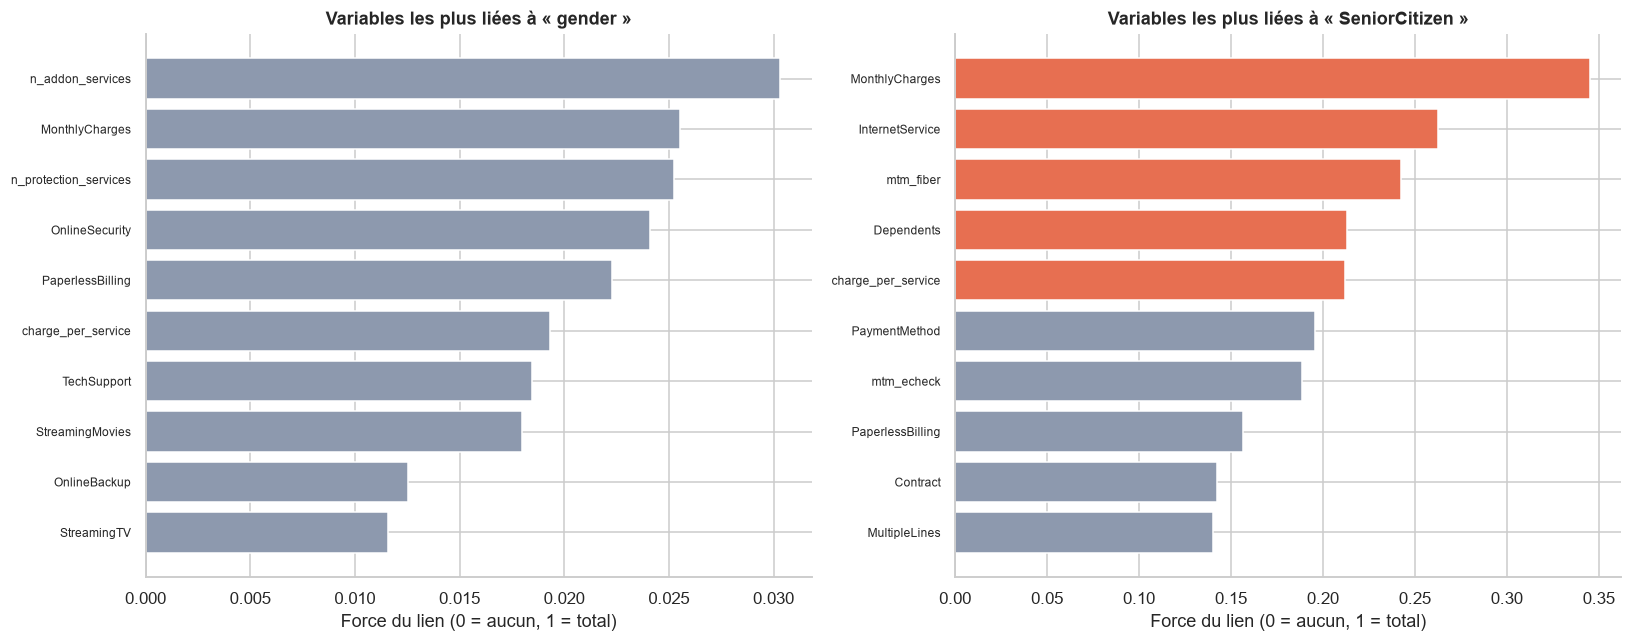

Lecture : une barre orange (lien ≥ 0,2) signale une variable qui pourrait deviner l'attribut sensible. Des barres grises = exclusion efficace.


In [21]:
h('### Recherche de proxys : lien entre chaque attribut sensible et les variables du modèle')
cat_feats = YN_FEATURES + MULTI_FEATURES + FLAG_FEATURES + ORDINAL_FEATURES
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, attr in zip(axes, ['gender', 'SeniorCitizen']):
    # catégorielles : V de Cramér ; numériques : effet rang-bisérial entre les deux groupes
    res = {c: cramers_v(train_fe[c], train_fe[attr]) for c in cat_feats}
    grp = train_fe[attr] == train_fe[attr].unique()[0]
    for c in NUM_FEATURES:
        u = stats.mannwhitneyu(train_fe.loc[grp, c], train_fe.loc[~grp, c])[0]
        res[c] = abs(2 * u / (grp.sum() * (~grp).sum()) - 1)
    s = pd.Series(res).sort_values(ascending=False).head(10).iloc[::-1]
    ax.barh(s.index, s.values, color=[C_CHURN if v >= .2 else C_GREY for v in s.values])
    ax.set_title(f'Variables les plus liées à « {attr} »'); ax.set_xlabel('Force du lien (0 = aucun, 1 = total)')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Lecture : une barre orange (lien ≥ 0,2) signale une variable qui pourrait deviner l\'attribut sensible. Des barres grises = exclusion efficace.')

---
## 10. Export
**Objectif :** sauvegarder tout ce dont le notebook 3 aura besoin dans `data/processed/`.

| Fichier | Contenu |
|---|---|
| `X_train_scaled.csv`, `X_test_scaled.csv` | Matrices avec mise à l'échelle (modèles linéaires) |
| `X_train_tree.csv`, `X_test_tree.csv` | Matrices sans mise à l'échelle (arbres, boosting, SHAP) |
| `y_train.csv`, `y_test.csv` | Cible (0/1) avec customerID |
| `train_features.csv`, `test_features.csv` | Données nettoyées + nouvelles variables, lisibles (non encodées) |
| `audit_sensitive_train.csv`, `audit_sensitive_test.csv` | gender et SeniorCitizen, pour l'audit d'équité |
| `preprocessor_scaled.joblib`, `preprocessor_tree.joblib` | Pipelines déjà ajustés, pour transformer de nouveaux clients |
| `feature_dictionary.csv` | Dictionnaire des variables |

In [24]:
def save(frame, name):
    frame.to_csv(OUT_DIR / name, index=False)

save(Xtr_scaled, 'X_train_scaled.csv');  save(Xte_scaled, 'X_test_scaled.csv')
save(Xtr_tree,   'X_train_tree.csv');    save(Xte_tree,   'X_test_tree.csv')
save(pd.DataFrame({'customerID': train_clean['customerID'].values, 'Churn': y_train.values}), 'y_train.csv')
save(pd.DataFrame({'customerID': test_clean['customerID'].values,  'Churn': y_test.values}),  'y_test.csv')
save(train_fe, 'train_features.csv');    save(test_fe, 'test_features.csv')
save(audit_train, 'audit_sensitive_train.csv'); save(audit_test, 'audit_sensitive_test.csv')
joblib.dump(pre_scaled, ROOT / 'models' / 'preprocessor_scaled.joblib')
joblib.dump(pre_tree,   ROOT / 'models' / 'preprocessor_tree.joblib')

# Dictionnaire des variables
descr = {
    'n_addon_services': 'Nombre de services optionnels actifs (0-6)', 'n_protection_services': 'Nombre de services de protection actifs (0-4)',
    'tenure_group': "Tranche d'ancienneté (0-6, 7-12, 13-24, 25-48, 49-72 mois)", 'is_new_customer': 'Ancienneté ≤ 12 mois',
    'auto_payment': 'Paiement automatique (virement ou carte)', 'avg_historical_charge': 'TotalCharges / tenure (intermédiaire)',
    'charge_trend': 'Prix actuel / facture moyenne passée − 1', 'charge_per_service': 'MonthlyCharges / (1 + nb de services)',
    'mtm_fiber': 'Contrat mensuel ET fibre optique', 'mtm_echeck': 'Contrat mensuel ET chèque électronique',
}
rows = [{'variable': v, 'origine': 'créée', 'description': descr[v], 'dans le modèle': v in ALL_FEATURES} for v in created]
rows += [{'variable': v, 'origine': 'brute', 'description': 'Colonne du jeu brut (nettoyée)', 'dans le modèle': True}
         for v in ALL_FEATURES if v not in created]
rows += [{'variable': c, 'origine': 'brute', 'description': w, 'dans le modèle': False} for c, w in EXCLUDED.items() if c != 'avg_historical_charge']
pd.DataFrame(rows).to_csv(OUT_DIR / 'feature_dictionary.csv', index=False)

files = sorted(OUT_DIR.glob('*'))
display(pd.DataFrame({'fichier': [f.name for f in files], 'taille (Ko)': [round(f.stat().st_size / 1024, 1) for f in files]}).set_index('fichier'))

,taille (Ko)
fichier,
audit_sensitive_test.csv,29.100
audit_sensitive_train.csv,116.400
feature_dictionary.csv,2.000
preprocessor_scaled.joblib,9.200
preprocessor_tree.joblib,8.700
test_features.csv,244.200
train_features.csv,979.900
X_test_scaled.csv,296.200
X_test_tree.csv,190.200


---
## 11. Synthèse

In [25]:
kept_created = [v for v in created if v in ALL_FEATURES]
facts = [
    f"**Données** : {len(clean):,} clients nettoyés (aucune ligne supprimée), séparés en {len(train_clean):,} pour l'entraînement et {len(test_clean):,} pour le test, avec le même taux de churn ({y_train.mean():.2%} et {y_test.mean():.2%}).",
    f"**Nettoyage** : {int(blank_mask.sum())} valeurs vides de TotalCharges mises à 0 (clients à tenure = 0) ; {len(SERVICE_COLS) + 1} variables de services simplifiées de 3 à 2 modalités.",
    f"**Feature engineering** : {len(created)} variables créées, dont {len(kept_created)} utilisées par le modèle.",
    f"**Sélection** : {len(EXCLUDED)} colonnes exclues (identifiant, attributs sensibles, doublons d'information).",
    f"**Matrice finale** : {Xtr_scaled.shape[1]} colonnes numériques, {int(Xtr_scaled.isna().sum().sum())} valeur manquante.",
    f"**Déséquilibre** : poids de classe {class_weight[1]:.2f} pour les partis, {class_weight[0]:.2f} pour les restés.",
    "**Responsible AI** : gender, SeniorCitizen et customerID sont hors de la matrice du modèle et conservés pour l'audit d'équité.",
]
for f in facts:
    h('- ' + f)

- **Données** : 7,043 clients nettoyés (aucune ligne supprimée), séparés en 5,634 pour l'entraînement et 1,409 pour le test, avec le même taux de churn (26.54% et 26.54%).

- **Nettoyage** : 11 valeurs vides de TotalCharges mises à 0 (clients à tenure = 0) ; 7 variables de services simplifiées de 3 à 2 modalités.

- **Feature engineering** : 10 variables créées, dont 9 utilisées par le modèle.

- **Sélection** : 5 colonnes exclues (identifiant, attributs sensibles, doublons d'information).

- **Matrice finale** : 32 colonnes numériques, 0 valeur manquante.

- **Déséquilibre** : poids de classe 1.88 pour les partis, 0.68 pour les restés.

- **Responsible AI** : gender, SeniorCitizen et customerID sont hors de la matrice du modèle et conservés pour l'audit d'équité.

### ➡️ Prochaine étape : Notebook 3 (modélisation)
Il partira des fichiers de `data/processed/` : entraînement des modèles, validation croisée, métriques adaptées au déséquilibre, explicabilité SHAP et audit d'équité.